In [1]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

Saving skripsi1.csv to skripsi1.csv


In [2]:
import pandas as pd
import re
# from langdetect import detect, DetectorFactory
df = pd.read_csv("skripsi1.csv")
df

,date,lang,urls,media,source,user_id,hashtags,is_quote,mentions,tweet_id,...,quoted_tweet_id,quoted_username,user_created_at,user_description,in_reply_to_user_id,user_statuses_count,user_followers_count,user_following_count,in_reply_to_status_id,in_reply_to_screen_name
0,2026-04-21T16:16:56,in,[],[],Twitter for Android,1527913902,[],True,[],2046624235121185116,...,2.046478e+18,geraldyoo_,Tue Jun 18 14:32:52 +0000 2013,"I was born in February,\nthat's why I love too...",NaN,22312,734,443,NaN,NaN
1,2026-04-21T14:07:32,in,[],[],Twitter for Android,1245421311435763712,[],False,"[{""name"":""🦈 SUROBOYOFESS 🐊"",""user_id"":""1152437...",2046591667625721882,...,NaN,NaN,Wed Apr 01 18:43:00 +0000 2020,"lagi fokus cari kerja, ngerjain freelance dan ...",1.152437e+18,42361,1603,807,2.046575e+18,sbyfess
2,2026-04-19T12:27:56,in,[],[],Twitter for iPhone,1673292316319285248,[],False,"[{""name"":""Deoxide ™"",""user_id"":""20058645587041...",2045841826540827135,...,NaN,NaN,Mon Jun 26 11:29:31 +0000 2023,NaN,2.005865e+18,57,0,18,2.045484e+18,TitaniumDeoxide
3,2026-04-19T02:10:01,in,[],[],Twitter for Android,1524086068919767040,[],False,"[{""name"":""Tanyarlfes"",""user_id"":""1371650588"",""...",2045686323173114238,...,NaN,NaN,Tue May 10 17:57:07 +0000 2022,Fullsun🌻🌻,1.371651e+09,1392,7,130,2.045456e+18,tanyarlfes
4,2026-04-19T18:21:13,in,[],[],Twitter for iPhone,734800004,[],False,"[{""name"":""Zan"",""user_id"":""1097211802717306880""...",2045930733202792855,...,NaN,NaN,Fri Aug 03 12:34:09 +0000 2012,"Gausah ngurusin aku, aku udah kurus🙏 || DM for...",1.097212e+18,295051,16120,2097,2.045769e+18,kapten__monyet
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3155,2025-01-07T12:14:26,in,[],[],Twitter for iPhone,1316596433714212864,[],False,[],1876603298926743767,...,NaN,NaN,Thu Oct 15 04:27:24 +0000 2020,Anak Shopee Affiliate yang review barang dulu ...,1.316596e+18,40078,901,589,1.876603e+18,JaneeeNoLimit
3156,2025-01-07T12:14:21,in,[],[],Twitter for iPhone,1316596433714212864,[],False,[],1876603277196075163,...,NaN,NaN,Thu Oct 15 04:27:24 +0000 2020,Anak Shopee Affiliate yang review barang dulu ...,1.316596e+18,40078,901,589,1.876603e+18,JaneeeNoLimit
3157,2025-01-07T10:10:40,in,[],[],Twitter for Android,1874711247893180416,[],True,[],1876572152528511403,...,1.876414e+18,gstytp,Thu Jan 02 06:56:31 +0000 2025,Aku Hiyabara 🦦🦫,NaN,1722,33,36,NaN,NaN
3158,2025-01-07T08:17:45,in,[],[],Twitter Web App,45138557,[],True,[],1876543732666990704,...,NaN,NaN,Sat Jun 06 14:27:54 +0000 2009,"If you're here to pick a fight with me, I'll b...",NaN,37532,747,1815,NaN,NaN


In [4]:
df_clean = df[['full_text']]
df_clean.head()

,full_text
0,"iya lagi, perkara gue pulang malem aja ditungg..."
1,@sbyfess kann cowo tuh kek pengen nikah oengen...
2,@TitaniumDeoxide Heran bgt ditanya kapan nikah...
3,@tanyarlfes Kak sama aku juga ga pernah pacara...
4,@kapten__monyet LAGI PENGEN UANG BANYAK BUAT U...


In [ ]:
# df = df[df['lang'] == 'in']  # Filter hanya teks berbahasa Indonesia
# df = df[['full_text']]
# df.rename(columns={'full_text': 'komen'}, inplace=True)
# df = df[~df['komen'].str.contains(r'@\w+', na=False)]  # Hapus mention
# df['komen'] = df['komen'].apply(lambda x: re.sub(r'[^\w\s]', '', x)) #Hapus Simbol
# df['komen'] = df['komen'].str.lower() #huruf kecil
# df.reset_index(drop=True, inplace=True)
# pd.set_option('display.max_colwidth', None)
# df

In [5]:
!pip install nltk sastrawi -q
import nltk
nltk.download('stopwords')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 6.1 MB/s eta 0:00:00


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [6]:
import pandas as pd
import re

# Filter bahasa Indonesia
df = df[df['lang'] == 'in']

# Ambil kolom full_text
df = df[['full_text']]

# Hapus data kosong
df = df.dropna(subset=['full_text'])

# Hapus duplikat
df = df.drop_duplicates(subset=['full_text'])

# Hapus mention
df['full_text'] = df['full_text'].str.replace(r'@\w+', '', regex=True)

# Hapus URL
df['full_text'] = df['full_text'].str.replace(r'http\S+|www\S+', '', regex=True)

# Hapus hashtag (# saja)
df['full_text'] = df['full_text'].str.replace(r'#', '', regex=True)

# Hapus angka
df['full_text'] = df['full_text'].str.replace(r'\d+', '', regex=True)

# Hapus simbol
df['full_text'] = df['full_text'].apply(lambda x: re.sub(r'[^\w\s]', '', x))

# Lowercase
df['full_text'] = df['full_text'].str.lower()

# Hapus spasi berlebih
df['full_text'] = df['full_text'].str.strip()
df['full_text'] = df['full_text'].str.replace(r'\s+', ' ', regex=True)

# Reset index
df.reset_index(drop=True, inplace=True)

df.head()

,full_text
0,iya lagi perkara gue pulang malem aja ditunggu...
1,kann cowo tuh kek pengen nikah oengen nikah do...
2,heran bgt ditanya kapan nikah kalau udah siap ...
3,kak sama aku juga ga pernah pacaran tapi kemar...
4,lagi pengen uang banyak buat umroh ortu dan bu...


In [7]:
negative_keywords = [
    # takut menikah
    "takut nikah",
    "takut menikah",
    "aku takut nikah",
    "jadi takut nikah",

    # tidak mau menikah
    "gamau nikah",
    "gak mau nikah",
    "ga mau nikah",
    "tidak mau nikah",

    # belum siap
    "belum siap nikah",
    "gak siap nikah",
    "ga siap nikah",
    "tidak siap nikah",

    # alasan negatif
    "takut cerai",
    "takut gagal",
    "takut salah pilih",
    "takut komitmen",
    "nikah mahal",
    "biaya nikah mahal",
    "nikah ribet",
    "overthinking nikah",
    "trauma nikah"
]

positive_keywords = [
    # keinginan menikah
    "pengen nikah",
    "ingin menikah",
    "mau nikah",
    "pengen menikah",

    # kesiapan
    "siap nikah",
    "siap menikah",
    "udah siap nikah",

    # pandangan positif
    "nikah itu indah",
    "bahagia menikah",
    "senang menikah",
    "menikah bahagia",
    "menikah ibadah",
    "nikah bikin bahagia"
]

def label_sentiment(text):
    text = text.lower()

    for word in negative_keywords:
        if word in text:
            return -1

    for word in positive_keywords:
        if word in text:
            return 1

    return None

df['label'] = df['full_text'].apply(label_sentiment)

df = df.dropna(subset=['label'])

df['label'] = df['label'].astype(int)

df.reset_index(drop=True, inplace=True)


In [8]:
from nltk.corpus import stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stop1 = set(stopwords.words('indonesian'))
stop2 = set(StopWordRemoverFactory().get_stop_words())

custom_stopwords = {
    'yg','gue','gua','gw',
    'tp','tapi','jd','jadi','bgt','banget',
    'udah','udh','dah','kalo','kalau','nya',
    'aja','sih','tuh','nih','loh','kok','kan',
    'emang','krn','karna','karena','org','orang',
    'dgn','dg','sama','blm','belum','jgn','juga',
    'aku','saya','kamu','dia','mereka',
    'wkwk','wkwkwk','haha','hehe', 'si','di','ke','dari','ini','itu','dan','atau','buat','untuk',
    'biar','gak','ga','gk','ndak','kagak', 'kek', 'kayak', 'kalo',
    'lah','deh','pun','kok','nan','re','rt','via','kali','kayaknya',
    'bang','kak','mas','mba','pas','lu','lo','elo','situ','emang'
}


all_stopwords = stop1.union(stop2).union(custom_stopwords)

def clean_text(text):
    words = text.split()
    words = [w for w in words if w not in all_stopwords]
    return ' '.join(words)

df['full_text'] = df['full_text'].apply(clean_text)

In [9]:
#STOPWORDS
# Download stopwords
from nltk.corpus import stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
# Gabungkan stopword nltk + sastrawi
stop_words = set(stopwords.words('indonesian'))

factory = StopWordRemoverFactory()
stop_words_sastrawi = set(factory.get_stop_words())

all_stopwords = stop_words.union(stop_words_sastrawi)

# Hapus beberapa kata penting agar tidak ikut terhapus
important_words = {'tidak', 'bukan', 'takut', 'nikah', 'menikah', 'belum'}
all_stopwords = all_stopwords - important_words

def remove_stopwords(text):
    words = text.split()
    filtered = [word for word in words if word not in all_stopwords]
    return " ".join(filtered)

df['full_text'] = df['full_text'].apply(remove_stopwords)

# Reset index
df.reset_index(drop=True, inplace=True)

In [ ]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from sklearn.feature_extraction.text import CountVectorizer

# stemming
stemmer = StemmerFactory().create_stemmer()
df['stemmed'] = df['full_text'].apply(stemmer.stem)
# tokenisasi
df['tokens'] = df['full_text'].str.split()

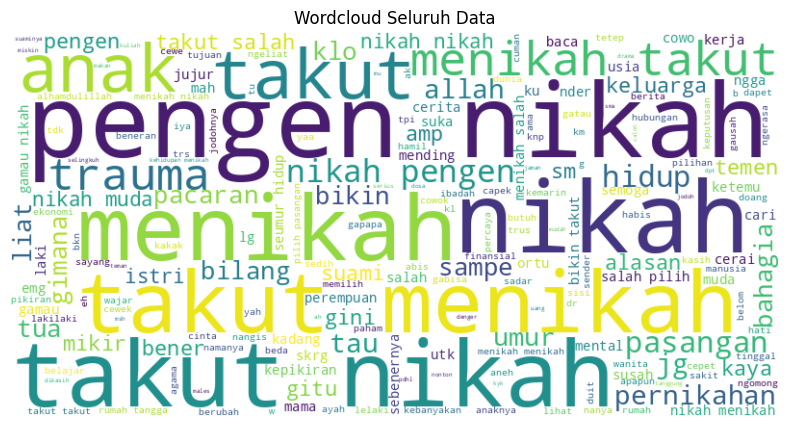

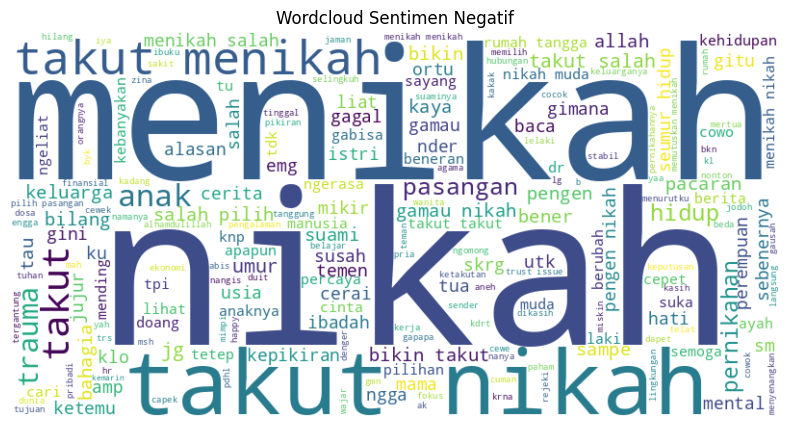

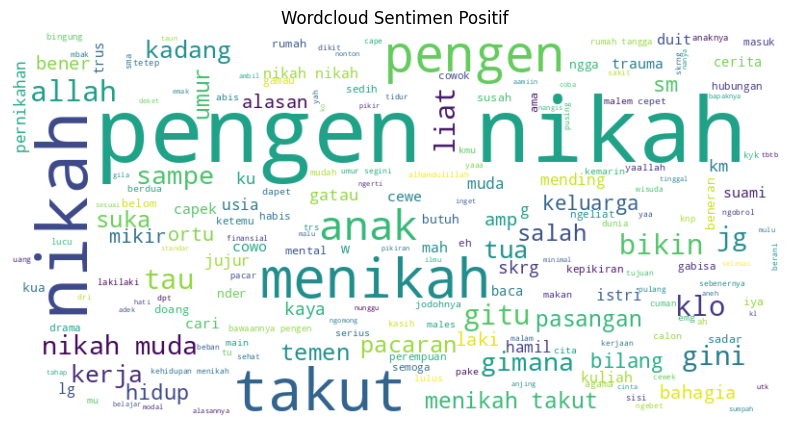

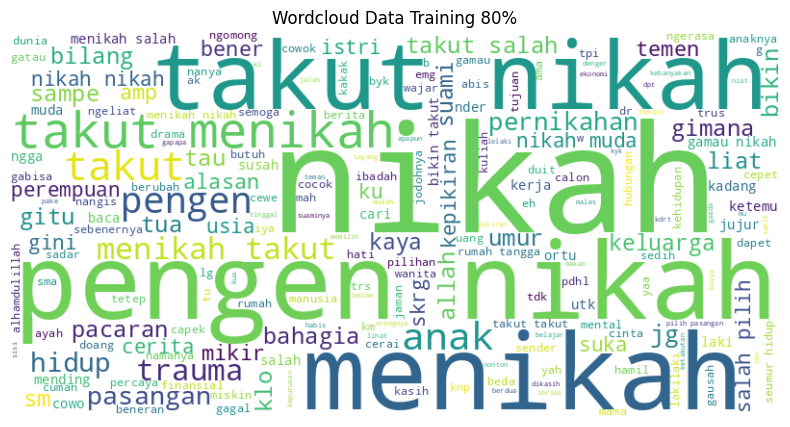

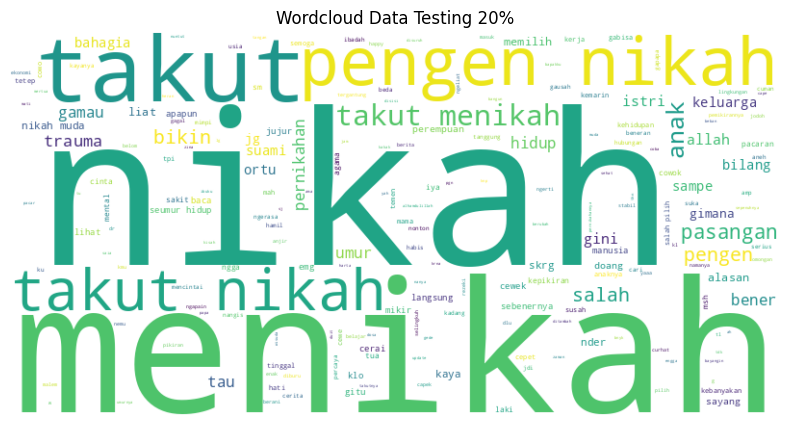

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split

# fungsi wordcloud
def wc(text, title):
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white'
    ).generate(text)

    plt.figure(figsize=(10,5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

# 1. seluruh data
wc(' '.join(df['full_text']), 'Wordcloud Seluruh Data')

# 2. negatif
wc(' '.join(df[df['label']==-1]['full_text']), 'Wordcloud Sentimen Negatif')

# 3. positif
wc(' '.join(df[df['label']==1]['full_text']), 'Wordcloud Sentimen Positif')

# 4. split terbaik (80:20)
X_train, X_test = train_test_split(
    df['full_text'],
    test_size=0.2,
    random_state=42
)

wc(' '.join(X_train), 'Wordcloud Data Training 80%')
wc(' '.join(X_test), 'Wordcloud Data Testing 20%')

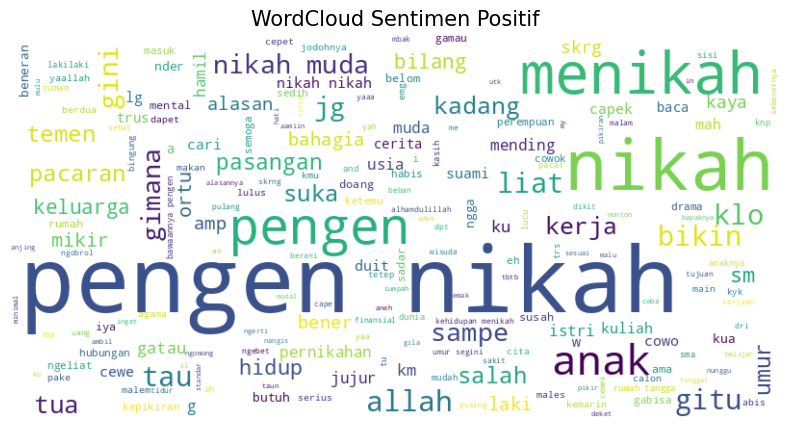

In [ ]:
# Gabungkan semua kata yang ingin kamu buang dari WordCloud Positif
blacklist_positif = {'takut', 'ga', 'tidak', 'belum', 'trauma', 'dan', 'buat', 'itu'}
all_stopwords_final = all_stopwords.union(blacklist_positif)

# Buat WordCloud hanya dari label 1
text_positif = " ".join(df[df['label'] == 1]['full_text'])

# Saat memanggil WordCloud, masukkan stopwords-nya
from wordcloud import WordCloud

wordcloud = WordCloud(
    stopwords=all_stopwords_final, # Pakai daftar yang sudah digabung
    background_color='white',
    width=800,
    height=400
).generate(text_positif)

# 4. Tampilkan (Bagian yang tadi kurang)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("WordCloud Sentimen Positif", fontsize=15)
plt.show()

/tmp/ipykernel_3804/2910596712.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


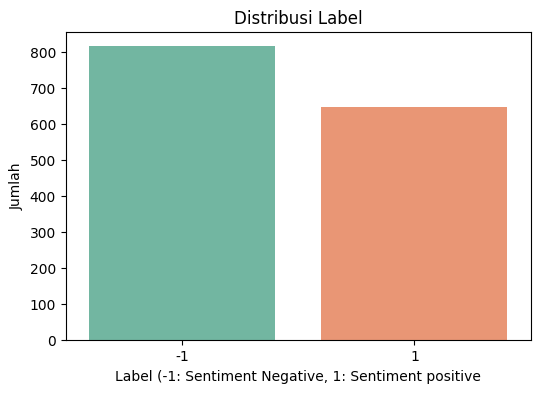

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi label
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Distribusi Label')
plt.xlabel('Label (-1: Sentiment Negative, 1: Sentiment positive')
plt.ylabel('Jumlah')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd

In [ ]:
X = df['full_text']
y = df['label']

split_tests = [0.1, 0.2, 0.3, 0.4, 0.5]

for test_size in split_tests:

    print("="*50)
    print(f"TEST SIZE = {test_size} | TRAIN = {int((1-test_size)*100)}%")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    tfidf = TfidfVectorizer(
        ngram_range=(1,2),
        max_features=5000
    )

    X_train_tfidf = tfidf.fit_transform(X_train)
    X_test_tfidf = tfidf.transform(X_test)

    model = SVC(kernel='linear')

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    acc = accuracy_score(y_test, y_pred)

    print("Accuracy:", round(acc,4))
    print(classification_report(y_test, y_pred))

TEST SIZE = 0.1 | TRAIN = 90%
Accuracy: 0.8776
              precision    recall  f1-score   support

          -1       0.83      0.98      0.90        82
           1       0.96      0.75      0.84        65

    accuracy                           0.88       147
   macro avg       0.90      0.86      0.87       147
weighted avg       0.89      0.88      0.87       147

TEST SIZE = 0.2 | TRAIN = 80%
Accuracy: 0.8805
              precision    recall  f1-score   support

          -1       0.85      0.96      0.90       163
           1       0.94      0.78      0.85       130

    accuracy                           0.88       293
   macro avg       0.89      0.87      0.88       293
weighted avg       0.89      0.88      0.88       293

TEST SIZE = 0.3 | TRAIN = 70%
Accuracy: 0.8841
              precision    recall  f1-score   support

          -1       0.86      0.94      0.90       245
           1       0.92      0.81      0.86       195

    accuracy                           0.

Ini harusnya yg terbaik itu 0.3

In [ ]:
best_test_size = 0.2

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=best_test_size,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    ngram_range=(1,2),
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)


In [ ]:
# PERBANDINGAN METODE IMBALANCED

!pip install imbalanced-learn -q

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.svm import SVC
import pandas as pd

methods = {
    "Baseline": None,
    "Class Weight Balanced": "balanced",
    "Random Oversampling": RandomOverSampler(random_state=42),
    "Random Undersampling": RandomUnderSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42)
}

hasil_method = []

for name, method in methods.items():

    print("="*60)
    print("METODE :", name)

    X_res, y_res = X_train_tfidf, y_train

    # sampling
    if name in ["Random Oversampling", "Random Undersampling", "SMOTE"]:
        X_res, y_res = method.fit_resample(X_train_tfidf, y_train)

    # model
    if name == "Class Weight Balanced":
        model = SVC(kernel='linear', class_weight='balanced')
    else:
        model = SVC(kernel='linear')

    # training
    model.fit(X_res, y_res)

    # prediksi
    y_pred = model.predict(X_test_tfidf)

    # evaluasi
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')

    print("Accuracy:", round(acc,4))
    print(classification_report(y_test, y_pred))

    hasil_method.append([
        name,
        round(acc,4),
        round(f1,4)
    ])

hasil_method = pd.DataFrame(
    hasil_method,
    columns=['Metode','Accuracy','F1 Score']
)

print("\n=== RANKING METODE TERBAIK ===")
print(hasil_method.sort_values(by='F1 Score', ascending=False))

METODE : Baseline
Accuracy: 0.8805
              precision    recall  f1-score   support

          -1       0.85      0.96      0.90       163
           1       0.94      0.78      0.85       130

    accuracy                           0.88       293
   macro avg       0.89      0.87      0.88       293
weighted avg       0.89      0.88      0.88       293

METODE : Class Weight Balanced
Accuracy: 0.884
              precision    recall  f1-score   support

          -1       0.86      0.94      0.90       163
           1       0.92      0.81      0.86       130

    accuracy                           0.88       293
   macro avg       0.89      0.88      0.88       293
weighted avg       0.89      0.88      0.88       293

METODE : Random Oversampling
Accuracy: 0.8805
              precision    recall  f1-score   support

          -1       0.86      0.94      0.90       163
           1       0.92      0.80      0.86       130

    accuracy                           0.88       293


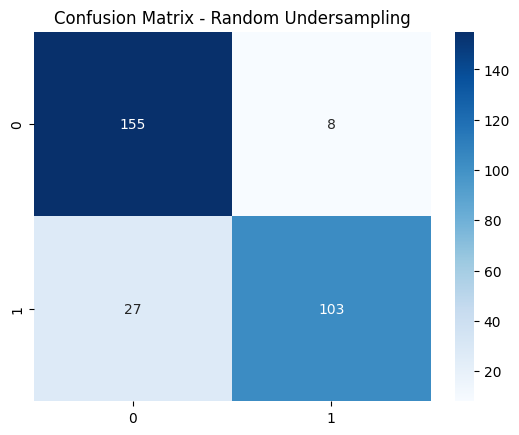

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Gunakan model terbaik (Undersampling)
# ... jalankan ulang fit untuk undersampling ...

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Undersampling')
plt.show()

# Topic Modeling


Percobaan ke 1

In [ ]:
!pip install gensim pyLDAvis -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 32.6 MB/s eta 0:00:00


In [ ]:
from gensim import corpora

# Kita contohkan ambil data negatif saja dulu untuk cari tahu "Alasan Takut Nikah"
data_topik = df[df['label'] == -1]['stemmed'].str.split()

# 1. Membuat Dictionary (Kumpulan kata unik)
dictionary = corpora.Dictionary(data_topik)

# 2. Membuat Corpus (Mengubah kata jadi frekuensi angka)
corpus = [dictionary.doc2bow(text) for text in data_topik]

print("Data siap diolah dengan metode LDA!")

Data siap diolah dengan metode LDA!


In [ ]:
from gensim.models import LdaModel

# Kita coba tentukan 3 topik dulu
num_topics = 3

# Melatih model LDA
lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=num_topics,
    random_state=42,
    update_every=1,
    chunksize=100,
    passes=10,
    alpha='auto',
    per_word_topics=True
)

# Menampilkan kata kunci untuk setiap topik
for idx, topic in lda_model.print_topics(-1):
    print(f"Topik {idx}: {topic}")

Topik 0: 0.101*"takut" + 0.101*"nikah" + 0.082*"meni" + 0.012*"salah" + 0.012*"hidup" + 0.011*"pasang" + 0.010*"anak" + 0.009*"bikin" + 0.008*"ken" + 0.007*"pilih"
Topik 1: 0.024*"anak" + 0.012*"sayang" + 0.012*"keluarga" + 0.010*"mikir" + 0.010*"cinta" + 0.009*"allah" + 0.009*"lingkung" + 0.009*"baca" + 0.008*"klw" + 0.007*"alam"
Topik 2: 0.027*"suami" + 0.018*"istri" + 0.015*"sufor" + 0.015*"rumah" + 0.013*"cocok" + 0.012*"tangga" + 0.009*"mahal" + 0.008*"serius" + 0.008*"ubah" + 0.007*"kondisi"


In [ ]:
import pyLDAvis.gensim_models
import pyLDAvis

# Siapkan visualisasi
pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(lda_model, corpus, dictionary)

# Tampilkan
vis

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.238979  0.011518       1        1  70.868305
1     -0.105426 -0.152550       2        1  17.423336
2     -0.133553  0.141032       3        1  11.708359, topic_info=       Term        Freq       Total Category  logprob  loglift
5     nikah  945.000000  945.000000  Default  30.0000  30.0000
53    takut  944.000000  944.000000  Default  29.0000  29.0000
75     meni  768.000000  768.000000  Default  28.0000  28.0000
9      anak  144.000000  144.000000  Default  27.0000  27.0000
329   suami   41.000000   41.000000  Default  26.0000  26.0000
...     ...         ...         ...      ...      ...      ...
1873  valid    9.295891   10.779498   Topic3  -5.1113   1.9968
81    istri   27.138613   36.322062   Topic3  -4.0399   1.8534
1612  mahal   13.464020   20.697055   Topic3  -4.7408   1.7149
73      knp    7.978329    9.451818   Topic3  -5.2641   1.9754
552     dar    8.282803   16.242996   Topic3  -5.2266   1.4714

[145 rows x 6 columns], token_table=      Topic      Freq    Term
term                         
207       1  0.976095    ajar
1466      3  0.981739  akibat
718       1  0.057806    alam
718       2  0.982695    alam
70        1  0.983653    alas
...     ...       ...     ...
227       1  1.001055    usia
1873      1  0.092769   valid
1873      3  0.834918   valid
3000      3  0.941406    yups
1870      2  0.926286    zina

[151 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3])

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Percobaan ke2

Output streaming akan dipotong hingga 5000 baris terakhir.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow(

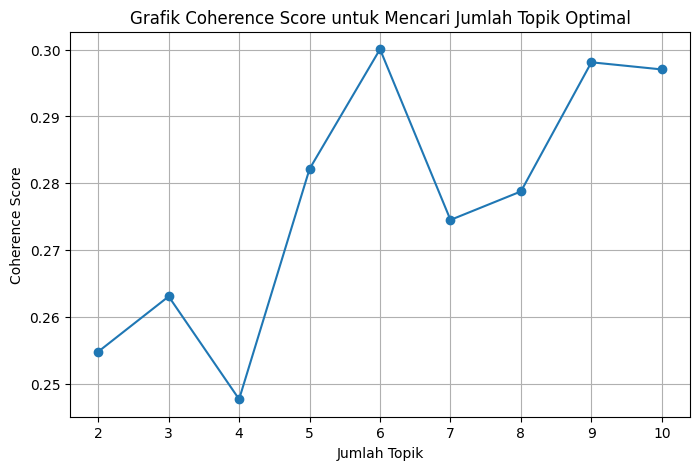

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
import matplotlib.pyplot as plt
from gensim import corpora
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel

# 1. Ambil data negatif
# Saran: Kita hapus kata 'nikah' dan 'takut' KHUSUS untuk topic modeling
# agar topik yang lebih spesifik (seperti 'biaya' atau 'mental') bisa muncul.
stop_topik = {'nikah', 'menikah', 'takut', 'meni'}

data_negatif = df[df['label'] == -1]['stemmed'].apply(
    lambda x: [w for w in str(x).split() if w not in stop_topik]
)

# 2. Siapkan Dictionary dan Corpus
dictionary = corpora.Dictionary(data_negatif)
corpus = [dictionary.doc2bow(text) for text in data_negatif]

# 3. Fungsi untuk menghitung Coherence Score
def compute_coherence_values(dictionary, corpus, texts, limit, start=2, step=1):
    coherence_values = []
    for num_topics in range(start, limit, step):
        # Training model LDA
        model = LdaModel(
            corpus=corpus,
            id2word=dictionary,
            num_topics=num_topics,
            random_state=42,
            passes=10 # Ditambah passes agar model lebih stabil
        )
        # Hitung skor kemiripan antar kata dalam topik
        coherencemodel = CoherenceModel(model=model, texts=texts, dictionary=dictionary, coherence='c_v')
        coherence_values.append(coherencemodel.get_coherence())
    return coherence_values

# 4. Jalankan perhitungan (2 sampai 10 topik)
limit_topik = 11
start_topik = 2
coherence_values = compute_coherence_values(
    dictionary=dictionary, corpus=corpus, texts=data_negatif, start=start_topik, limit=limit_topik
)

# 5. Visualisasi Grafik
x = range(start_topik, limit_topik, 1)
plt.figure(figsize=(8, 5))
plt.plot(x, coherence_values, marker='o')
plt.xlabel("Jumlah Topik")
plt.ylabel("Coherence Score")
plt.title("Grafik Coherence Score untuk Mencari Jumlah Topik Optimal")
plt.grid(True)
plt.show()

In [ ]:
# Model LDA Final dengan 4 Topik
lda_model_4 = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=4,
    random_state=42,
    passes=15
)

# Tampilkan Visualisasi Interaktif
import pyLDAvis.gensim_models
vis = pyLDAvis.gensim_models.prepare(lda_model_4, corpus, dictionary)
pyLDAvis.display(vis)

Output streaming akan dipotong hingga 5000 baris terakhir.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow(

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import pandas as pd

# Fungsi untuk mencari topik dominan di setiap tweet
def get_dominant_topic(lda_model, corpus):
    topic_list = []
    for i, row in enumerate(lda_model[corpus]):
        row = sorted(row[0], key=lambda x: (x[1]), reverse=True)
        topic_list.append(row[0][0]) # Ambil ID topik dengan probabilitas tertinggi
    return topic_list

# Tambahkan ke dataframe
df_negatif = df[df['label'] == -1].copy()
df_negatif['dominant_topic'] = get_dominant_topic(lda_model_4, corpus)

# Lihat distribusinya
print(df_negatif['dominant_topic'].value_counts(normalize=True))

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

TypeError: 'int' object is not subscriptable

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Percobaan ke3

In [ ]:
from gensim import corpora
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel
import matplotlib.pyplot as plt

# Ambil data negatif & bersihkan kata umum
data_negatif = df[df['label'] == -1]['stemmed'].copy()
custom_stop = {
    # Kata kunci utama (karena sudah pasti ada di semua tweet)
    'nikah', 'menikah', 'takut', 'meni', 'pernikahan',

    # Kata gaul/singkatan Twitter
    'yg', 'kalo', 'pas', 'ga', 'gak', 'aja', 'udah', 'udah', 'deh', 'sih',
    'kek', 'banget', 'bgt', 'tau', 'tahu', 'jadi', 'jd', 'kayak', 'kyk',

    # Kata ganti/umum
    'orang', 'kita', 'kalo', 'kalo', 'biar', 'bikin', 'buat', 'pake', 'pakai',
    'emang', 'sama', 'dari', 'ke', 'di', 'ini', 'itu', 'dan', 'atau'
}
data_ready = data_negatif.apply(lambda x: [w for w in str(x).split() if w not in custom_stop])

# Buat Dictionary dan Corpus
dictionary = corpora.Dictionary(data_ready)
corpus = [dictionary.doc2bow(text) for text in data_ready]

print("Step 1 Selesai: Data siap diuji!")

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Step 1 Selesai: Data siap diuji!


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Output streaming akan dipotong hingga 5000 baris terakhir.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow(

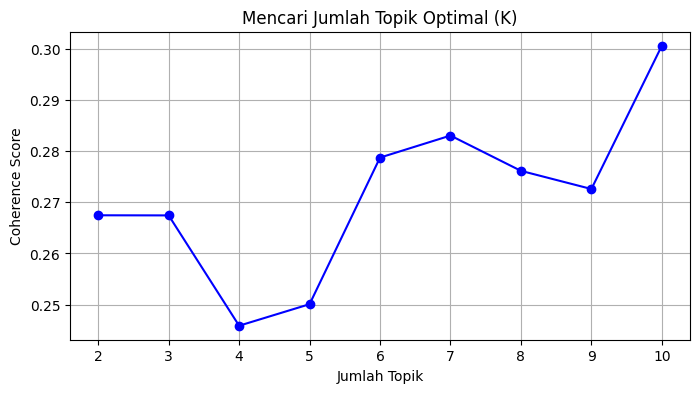

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
def compute_coherence_values(dictionary, corpus, texts, limit, start=2, step=1):
    coherence_values = []
    for num_topics in range(start, limit, step):
        model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=num_topics, random_state=42)
        coherencemodel = CoherenceModel(model=model, texts=texts, dictionary=dictionary, coherence='c_v')
        coherence_values.append(coherencemodel.get_coherence())
    return coherence_values

# Jalankan perhitungan 2-10 topik
start, limit, step = 2, 11, 1
coherence_values = compute_coherence_values(dictionary, corpus, data_ready, limit, start, step)

# Plot Grafiknya
x = range(start, limit, step)
plt.figure(figsize=(8, 4))
plt.plot(x, coherence_values, marker='o', color='b')
plt.xlabel("Jumlah Topik")
plt.ylabel("Coherence Score")
plt.title("Mencari Jumlah Topik Optimal (K)")
plt.grid(True)
plt.show()

In [ ]:
# Training Model Final
lda_model_final = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=4,
    random_state=42,
    passes=15
)

# Tampilkan kata kuncinya
print("\n=== KATA KUNCI 4 TOPIK TERPILIH ===")
for idx, topic in lda_model_final.print_topics(num_words=10):
    print(f"Topik {idx}: {topic}")

Output streaming akan dipotong hingga 5000 baris terakhir.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow(


=== KATA KUNCI 4 TOPIK TERPILIH ===
Topik 0: 0.018*"pasang" + 0.013*"hidup" + 0.011*"suami" + 0.011*"salah" + 0.009*"anak" + 0.007*"gamau" + 0.006*"pilih" + 0.006*"percaya" + 0.006*"umur" + 0.006*"ken"
Topik 1: 0.013*"bahagia" + 0.012*"anak" + 0.010*"hidup" + 0.008*"trauma" + 0.007*"salah" + 0.006*"alas" + 0.006*"nder" + 0.005*"umur" + 0.005*"kaya" + 0.005*"pasang"
Topik 2: 0.017*"pilih" + 0.015*"hidup" + 0.014*"trauma" + 0.013*"salah" + 0.011*"anak" + 0.010*"umur" + 0.008*"rumah" + 0.007*"tangga" + 0.006*"perempuan" + 0.006*"pacar"
Topik 3: 0.017*"salah" + 0.014*"anak" + 0.010*"ken" + 0.009*"pasang" + 0.009*"trauma" + 0.008*"pikir" + 0.006*"gamau" + 0.006*"bener" + 0.006*"hidup" + 0.006*"muda"


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
import pyLDAvis.gensim_models
import pyLDAvis

pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(lda_model_final, corpus, dictionary)
pyLDAvis.display(vis)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Percobaan

In [ ]:
# from sklearn.model_selection import train_test_split

# X = df['full_text']
# y = df['label']

# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )

In [ ]:
# # Tampilkan data berlabel positif
# data_positif = df[df['label'] == -1]

# data_positif.to_csv("data_sentimen_negatif.csv", index=False, encoding='utf-8-sig')

In [ ]:
# from sklearn.feature_extraction.text import TfidfVectorizer

# tfidf = TfidfVectorizer()

# X_train_tfidf = tfidf.fit_transform(X_train)
# X_test_tfidf = tfidf.transform(X_test)

In [ ]:
# import matplotlib.pyplot as plt
# from wordcloud import WordCloud

# text = ' '.join(df['full_text'])
# wordcloud = WordCloud(
#     width=800,
#     height=400,
#     background_color='white'
# ).generate(text)
# plt.figure(figsize=(10,5))
# plt.imshow(wordcloud, interpolation='bilinear')
# plt.axis('off')
# plt.show()

/tmp/ipykernel_14976/2910596712.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


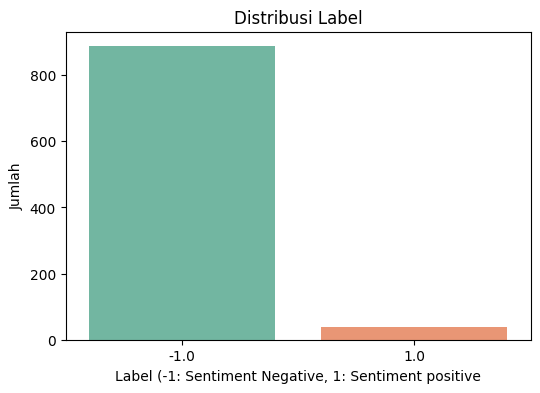

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi label
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Distribusi Label')
plt.xlabel('Label (-1: Sentiment Negative, 1: Sentiment positive')
plt.ylabel('Jumlah')
plt.show()

In [ ]:
# ==========================================
# PERBANDINGAN METODE IMBALANCED DATA
# ==========================================

# install jika belum ada
!pip install imbalanced-learn -q

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

# ===============================
# SPLIT DATA
# ===============================
X = df['full_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# TFIDF
tfidf = TfidfVectorizer(ngram_range=(1,2), max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# ===============================
# LIST METODE
# ===============================
methods = {
    "Tanpa Imbalance": None,
    "Class Weight Balanced": "balanced",
    "Random Oversampling": RandomOverSampler(random_state=42),
    "Random Undersampling": RandomUnderSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42)
}

# ===============================
# LOOP TEST
# ===============================
for name, method in methods.items():

    print("="*60)
    print("METODE :", name)

    X_res, y_res = X_train_tfidf, y_train

    # oversampling / undersampling
    if name in ["Random Oversampling", "Random Undersampling", "SMOTE"]:
        X_res, y_res = method.fit_resample(X_train_tfidf, y_train)

    # model
    if name == "Class Weight Balanced":
        model = SVC(kernel='linear', class_weight='balanced')
    else:
        model = SVC(kernel='linear')

    # train
    model.fit(X_res, y_res)

    # prediksi
    y_pred = model.predict(X_test_tfidf)

    # hasil
    print("Accuracy :", round(accuracy_score(y_test, y_pred),4))
    print(classification_report(y_test, y_pred))

ValueError: Input y contains NaN.

In [ ]:
from sklearn.metrics import accuracy_score

# model final
model = SVC(kernel='linear', class_weight='balanced')

# train
model.fit(X_train_tfidf, y_train)

# prediksi train
y_train_pred = model.predict(X_train_tfidf)

# prediksi test
y_test_pred = model.predict(X_test_tfidf)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy :", round(train_acc,4))
print("Testing Accuracy  :", round(test_acc,4))
print("Gap :", round(train_acc - test_acc,4))

Training Accuracy : 1.0
Testing Accuracy  : 0.9611
Gap : 0.0389


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

pipeline = make_pipeline(
    TfidfVectorizer(ngram_range=(1,2), max_features=5000),
    SVC(kernel='linear', class_weight='balanced')
)

scores = cross_val_score(
    pipeline,
    df['full_text'],
    df['label'],
    cv=5,
    scoring='f1_weighted'
)

print("CV Scores:", scores)
print("Mean CV :", scores.mean())
print("Std CV  :", scores.std())

CV Scores: [0.95407294 0.94594595 0.96534207 0.96234335 0.95382615]
Mean CV : 0.956306090707949
Std CV  : 0.006878474084879001


In [ ]:
# text_neg = ' '.join(df[df['label'] == -1]['full_text'])

# wordcloud_neg = WordCloud(width=800, height=400, background_color='white').generate(text_neg)

# plt.figure(figsize=(10,5))
# plt.imshow(wordcloud_neg, interpolation='bilinear')
# plt.axis('off')
# plt.title("WordCloud Sentimen Negatif")
# plt.show()

In [ ]:
# text_pos = ' '.join(df[df['label'] == 1]['full_text'])

# wordcloud_pos = WordCloud(width=800, height=400, background_color='white').generate(text_pos)

# plt.figure(figsize=(10,5))
# plt.imshow(wordcloud_pos, interpolation='bilinear')
# plt.axis('off')
# plt.title("WordCloud Sentimen Positif")
# plt.show()

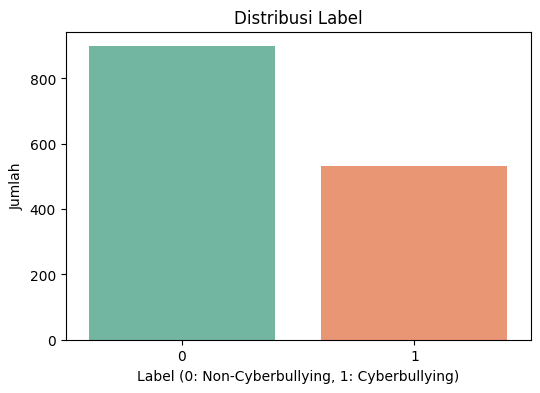

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi label
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Distribusi Label')
plt.xlabel('Label (0: Non-Cyberbullying, 1: Cyberbullying)')
plt.ylabel('Jumlah')
plt.show()

In [ ]:
# from sklearn.pipeline import Pipeline
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.svm import SVC
# from sklearn.model_selection import train_test_split, GridSearchCV
# from sklearn.metrics import classification_report, accuracy_score
# import numpy as np

# # Data splitting
# X = df['komen']
# y = df['label']
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# # Pipeline dengan SVC probability=True
# pipeline = Pipeline([
#     ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words=None)),
#     ('svc', SVC(probability=True))  # Aktifkan probabilitas
# ])

# # GridSearchCV dengan parameter tuning
# param_grid = {
#     'tfidf__max_features': [3000, 5000, 10000],
#     'tfidf__ngram_range': [(1, 1), (1, 2)],
#     'svc__C': [0.1, 1, 10],
#     'svc__kernel': ['linear', 'rbf'],
#     'svc__gamma': ['scale', 'auto']
# }
# grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', verbose=2, n_jobs=-1)
# grid_search.fit(X_train, y_train)

# # Model terbaik
# best_model = grid_search.best_estimator_
# print("Best Parameters:", grid_search.best_params_)

# # Evaluasi
# y_pred = best_model.predict(X_test)
# accuracy = accuracy_score(y_test, y_pred)
# print(f"Accuracy: {accuracy}")
# print("Classification Report:")
# print(classification_report(y_test, y_pred))


Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best Parameters: {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'linear', 'tfidf__max_features': 3000, 'tfidf__ngram_range': (1, 2)}
Accuracy: 0.9685314685314685
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       180
           1       0.97      0.94      0.96       106

    accuracy                           0.97       286
   macro avg       0.97      0.96      0.97       286
weighted avg       0.97      0.97      0.97       286



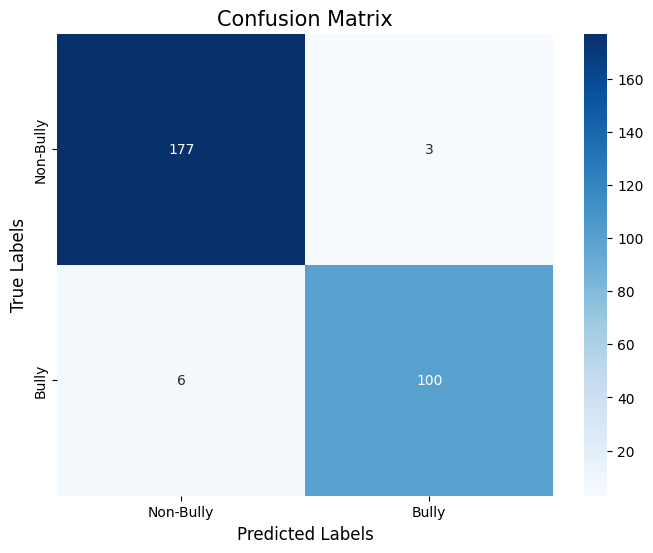

In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# from sklearn.metrics import confusion_matrix

# # Hitung confusion matrix
# cm = confusion_matrix(y_test, y_pred)
# labels = ['Non-Bully', 'Bully']

# # Plot confusion matrix
# plt.figure(figsize=(8, 6))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
# plt.xlabel('Predicted Labels', fontsize=12)
# plt.ylabel('True Labels', fontsize=12)
# plt.title('Confusion Matrix', fontsize=15)
# plt.show()
